In [ ]:
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install sklearn
!pip install searborn

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'sklearn' when getting requirements to build wheel
ERROR: Could not find a version that satisfies the requirement searborn (from versions: none)
ERROR: No matching distribution found for searborn


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
df= pd.read_csv('/content/social_media_engagement_5000.csv')
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


# **Check the dataset dimensions**

In [ ]:
print("Number of rows and columns:", df.shape)
print("Column names:", df.columns)


Number of rows and columns: (5000, 19)
Column names: Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [ ]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


# Convert date columns into datetime format

In [ ]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    errors='coerce'
)

# Check the data type
print(df['posted_at'].dtype)

# Display first five dates
print(df['posted_at'].head())

datetime64[ns]
0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[ns]


/tmp/ipykernel_405/2036260241.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_at'] = pd.to_datetime(


# Perform basic NumPy array operations

In [ ]:


likes = np.array([100, 200, 300, 400, 500])

print("Array:", likes)
print("Sum:", np.sum(likes))
print("Mean:", np.mean(likes))
print("Maximum:", np.max(likes))
print("Minimum:", np.min(likes))
print("Array + 10:", likes + 10)


Array: [100 200 300 400 500]
Sum: 1500
Mean: 300.0
Maximum: 500
Minimum: 100
Array + 10: [110 210 310 410 510]


# **Task 2 - Data Cleaning**

In [ ]:
# Check missing values

print(df.isnull().sum())



user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [ ]:
# Check missing values using isna()

print(df.isna().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [ ]:
#Calculate the percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)


user_id             0.0
age                 3.0
gender              3.0
country             0.0
post_id             0.0
post_type           0.0
post_category       0.0
likes               3.0
comments            3.0
shares              3.0
watch_time_sec      0.0
impression_count    0.0
posted_at           0.0
follower_count      0.0
is_verified         0.0
device_type         0.0
sentiment           3.0
hashtags            0.0
engagement_rate     0.0
dtype: float64


In [ ]:

# Handle missing numerical values using median

numeric_columns = df.select_dtypes(include=np.number).columns

# Fill missing numerical values using median
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing numerical values handled")


Missing numerical values handled


In [ ]:
#Handle missing categorical values using mode


categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing categorical values handled")


Missing categorical values handled


In [ ]:
#Forward fill and backward fill

# Forward fill missing values
df['posted_at'] = df['posted_at'].ffill()

# Backward fill missing values
df['posted_at'] = df['posted_at'].bfill()

In [ ]:
# Check missing values
print("Missing dates:", df['posted_at'].isnull().sum())

# Display first five rows
print(df['posted_at'].head())

Missing dates: 0
0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[ns]


In [ ]:

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

print("Duplicates removed successfully")


Duplicate rows: 0
Duplicates removed successfully


In [ ]:

# Convert numeric columns
numeric_cols = [
    'likes', 'comments', 'shares',
    'impressions', 'watch_time',
    'engagement_rate', 'followers', 'age'
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print(df.dtypes)


user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


In [ ]:
#gender labels
df['gender'] = df['gender'].astype('string').str.strip().str.lower()

df['gender'] = df['gender'].replace({
    'm': 'male',
    'f': 'female',
    'woman': 'female',
    'man': 'male'
})

print(df['gender'].value_counts())


gender
male      1849
other     1581
female    1570
Name: count, dtype: Int64


In [ ]:

# Check negative engagement values
engagement_columns = ['likes', 'comments', 'shares',
                      'impressions', 'watch_time']

for col in engagement_columns:
    if col in df.columns:
        print(col, "Negative values:", (df[col] < 0).sum())

# Replace negative values with NaN
for col in engagement_columns:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan


likes Negative values: 0
comments Negative values: 0
shares Negative values: 0


In [ ]:

# Extract hashtag count
df['hashtag_count'] = df['hashtags'].fillna('').apply(
    lambda x: x.count('#')
)

# Display the result
print(df[['hashtags', 'hashtag_count']].head(10))

                  hashtags  hashtag_count
0    #foodie #travel #love              3
1                 #fitness              1
2                  #foodie              1
3      #music #foodie #fun              3
4                  #travel              1
5                 #fitness              1
6                   #music              1
7  #travel #music #fitness              3
8     #music #fun #fitness              3
9         #lifestyle #love              2


In [ ]:

df['sentiment'] = (
    df['sentiment']
    .astype('string')
    .str.strip()
    .str.lower()
)

print(df['sentiment'].value_counts())


sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: Int64


# Task 3 – Data Exploration Using Pandas

In [ ]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [ ]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [ ]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Shape: (5000, 20)

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   string        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [ ]:
df.dtypes

,0
user_id,int64
age,float64
gender,string[python]
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [ ]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [ ]:
print(df['post_type'].value_counts())
print(df['gender'].value_counts())
print(df['country'].value_counts())
print(df['sentiment'].value_counts())


post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
gender
male      1849
other     1581
female    1570
Name: count, dtype: Int64
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: Int64


In [ ]:

print("Unique post types:")
print(df['post_type'].unique())

print("\nUnique countries:")
print(df['country'].unique())


Unique post types:
['image' 'reel' 'text' 'video']

Unique countries:
['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']


In [ ]:
print("Unique post types:", df['post_type'].nunique())
print("Unique countries:", df['country'].nunique())
print("Unique sentiments:", df['sentiment'].nunique())

Unique post types: 4
Unique countries: 10
Unique sentiments: 3


In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

print(correlation_matrix)

                   user_id       age  ...  engagement_rate  hashtag_count
user_id           1.000000 -0.006688  ...        -0.004282      -0.013692
age              -0.006688  1.000000  ...         0.008039       0.007173
post_id           0.020051 -0.013153  ...         0.010139       0.007344
likes             0.025811 -0.036322  ...         0.093520      -0.002190
comments         -0.033395 -0.007284  ...         0.000051      -0.015230
shares            0.013763  0.013871  ...         0.021724       0.013379
watch_time_sec   -0.016847  0.005542  ...        -0.001148      -0.023301
impression_count  0.015326  0.013322  ...        -0.232226      -0.002714
follower_count    0.010124 -0.024894  ...         0.002292       0.008802
engagement_rate  -0.004282  0.008039  ...         1.000000       0.005319
hashtag_count    -0.013692  0.007173  ...         0.005319       1.000000

[11 rows x 11 columns]


In [ ]:
avg_likes = df.groupby('post_type')['likes'].mean()

print(avg_likes)


post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64


In [ ]:
avg_likes = df.groupby('post_type')['likes'].mean()

print(avg_likes)


post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64


# Task 4 -  Data Wrangling

In [ ]:

# Create engagement score

df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

print(df[['likes', 'comments', 'shares',
          'engagement_score']].head())



     likes  comments  shares  engagement_score
0   7011.0     354.0  1157.0            8522.0
1  11750.0    2606.0  1807.0           16163.0
2   4862.0     344.0   955.0            6161.0
3   5350.0    1083.0  1049.0            7482.0
4  12682.0    2735.0  1300.0           16717.0


In [ ]:
df['log_likes'] = np.log1p(df['likes'])

df[['likes', 'log_likes']].head()

,likes,log_likes
0,7011.0,8.855378
1,11750.0,9.371694
2,4862.0,8.489411
3,5350.0,8.585039
4,12682.0,9.448018


In [ ]:

# Create a new column to count hashtags

df['hashtag_count'] = df['hashtags'].fillna('').apply(
    lambda x: x.count('#')
)

# Display the result
print(df[['hashtags', 'hashtag_count']].head(10))



                  hashtags  hashtag_count
0    #foodie #travel #love              3
1                 #fitness              1
2                  #foodie              1
3      #music #foodie #fun              3
4                  #travel              1
5                 #fitness              1
6                   #music              1
7  #travel #music #fitness              3
8     #music #fun #fitness              3
9         #lifestyle #love              2


In [ ]:

post_summary = df.groupby('post_type').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean'
})

print(post_summary)

                  likes     comments       shares  engagement_score
post_type                                                          
image      10104.865277  1525.235766  1019.289495      12649.390537
reel       10037.802416  1504.187062   982.042089      12524.031567
text       10100.148193  1499.106024  1013.989558      12613.243775
video      10188.600000  1479.160000   996.834286      12664.594286


In [ ]:

# Group data by country

country_summary = df.groupby('country').agg({
    'likes': 'mean',
    'impression_count': 'mean',
    'engagement_rate': 'mean'
})

print(country_summary)


                  likes  impression_count  engagement_rate
country                                                   
Australia  10294.124746      48346.383367         1.324339
Brazil      9886.689484      49193.174603         1.540704
Canada     10063.066277      48703.150097         0.916659
France     10372.876008      51727.673387         1.146402
Germany    10130.458163      48605.406122         0.759000
India       9962.468224      52462.386916         0.655005
Japan      10088.862288      49616.135593         0.769623
UAE        10227.487078      48928.413519         1.112352
UK          9935.650101      51119.393509         0.850966
USA        10122.361277      51263.872255         0.576580


In [ ]:

sentiment_summary = df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

print(sentiment_summary)


                  likes     comments       shares  engagement_rate
sentiment                                                         
negative   10208.096875  1516.094792  1007.307292         1.038486
neutral     9923.194499  1528.404060   996.565160         0.991170
positive   10180.062077  1480.650617  1005.086749         0.919744


# Task 5 - Statistical Analysis

In [ ]:

# Columns for statistical analysis

columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

# Calculate Mean
print("MEAN")

for col in columns:
    print(col, ":", df[col].mean())



MEAN
likes : 10106.9974
comments : 1502.0398
shares : 1002.9106
watch_time_sec : 4014.5032
engagement_rate : 0.9643560291583999
follower_count : 393698.2248


In [ ]:

print("MEDIAN")

for col in columns:
    print(col, ":", df[col].median())


MEDIAN
likes : 10105.5
comments : 1497.0
shares : 1012.0
watch_time_sec : 4034.5
engagement_rate : 0.2538959065
follower_count : 388982.0


In [ ]:

print("MODE")

for col in columns:
    print(col, ":", df[col].mode().tolist())


MODE
likes : [10105.5]
comments : [1497.0]
shares : [1012.0]
watch_time_sec : [916, 2145, 4360, 7003, 7688]
engagement_rate : [0.006362909, 0.007420223, 0.012675682, 0.012692458, 0.015004762, 0.01504267, 0.016487189, 0.017929235, 0.019504892, 0.020066556, 0.021235787, 0.021406797, 0.021568383, 0.022186567, 0.022462103, 0.022620033, 0.022873942, 0.022989779, 0.02345363, 0.02373806, 0.023777224, 0.02407874, 0.024382109, 0.024402536, 0.024923189, 0.02501037, 0.025869521, 0.026288553, 0.026700739, 0.027003808, 0.027072249, 0.027075357, 0.027418349, 0.027635797, 0.028038518, 0.02841515, 0.029213767, 0.029438002, 0.029453217, 0.029488963, 0.029841738, 0.029846097, 0.030060482, 0.030151749, 0.030902223, 0.03094009, 0.031204993, 0.03146206, 0.031744116, 0.032189657, 0.032536465, 0.03259756, 0.032874078, 0.032900135, 0.032971649, 0.033250084, 0.033260656, 0.033362339, 0.033680167, 0.033761313, 0.033874496, 0.034002429, 0.034326146, 0.035015642, 0.035110716, 0.03516921, 0.035468124, 0.035655041,

In [ ]:

print("STANDARD DEVIATION")

for col in columns:
    print(col, ":", df[col].std())


STANDARD DEVIATION
likes : 5702.293017183876
comments : 856.3933120458967
shares : 570.8551999758862
watch_time_sec : 2308.096459042085
engagement_rate : 5.318029222661535
follower_count : 230927.88453461014


In [ ]:

print("VARIANCE")

for col in columns:
    print(col, ":", df[col].var())


VARIANCE
likes : 32516145.653823998
comments : 733409.5049169405
shares : 325875.65933950903
watch_time_sec : 5327309.26424261
engagement_rate : 28.281434813082043
follower_count : 53327687855.63023


In [ ]:

print("PERCENTILES")

for col in columns:
    print("\n", col)
    print("25th Percentile:", df[col].quantile(0.25))
    print("50th Percentile:", df[col].quantile(0.50))
    print("75th Percentile:", df[col].quantile(0.75))


PERCENTILES

 likes
25th Percentile: 5235.0
50th Percentile: 10105.5
75th Percentile: 14959.0

 comments
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25

 shares
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0

 watch_time_sec
25th Percentile: 2017.75
50th Percentile: 4034.5
75th Percentile: 6020.25

 engagement_rate
25th Percentile: 0.14578108750000002
50th Percentile: 0.2538959065
75th Percentile: 0.504793702

 follower_count
25th Percentile: 194480.0
50th Percentile: 388982.0
75th Percentile: 589744.25


In [ ]:

for col in columns:
    print("\n", col)
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())



 likes
Skewness: -0.006893616532184278
Kurtosis: -1.1499923609078424

 comments
Skewness: 0.0038017289479831415
Kurtosis: -1.1443748352968992

 shares
Skewness: -0.014653583910311461
Kurtosis: -1.1468565626589917

 watch_time_sec
Skewness: -0.018196273193231846
Kurtosis: -1.195651797070188

 engagement_rate
Skewness: 18.781270878869154
Kurtosis: 482.9917386319569

 follower_count
Skewness: 0.04111777394961326
Kurtosis: -1.1894740478821386


In [ ]:

statistics = df[columns].agg([
    'mean',
    'median',
    'std',
    'var',
    'min',
    'max'
])

print(statistics)


               likes       comments  ...  engagement_rate  follower_count
mean    1.010700e+04    1502.039800  ...         0.964356    3.936982e+05
median  1.010550e+04    1497.000000  ...         0.253896    3.889820e+05
std     5.702293e+03     856.393312  ...         5.318029    2.309279e+05
var     3.251615e+07  733409.504917  ...        28.281435    5.332769e+10
min     1.000000e+01       0.000000  ...         0.006363    8.700000e+01
max     1.999800e+04    2999.000000  ...       191.504348    7.995330e+05

[6 rows x 6 columns]


# Task 6 - Data Visualization

Scatter plot


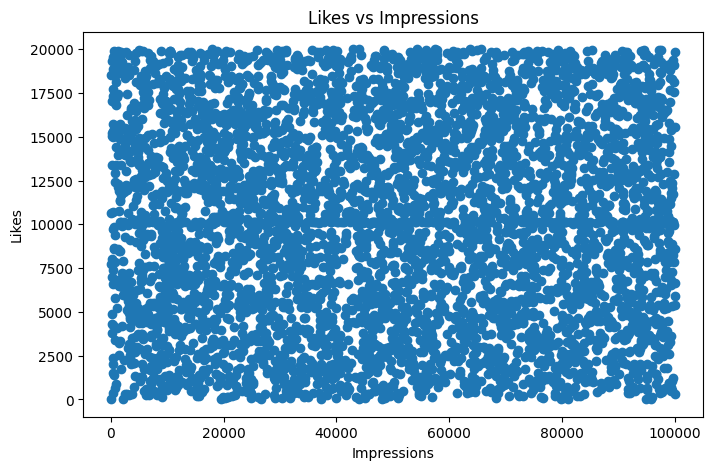

In [82]:
print('Scatter plot')

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df['impression_count'],
    df['likes']
)

plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')

plt.show()



Line Plot


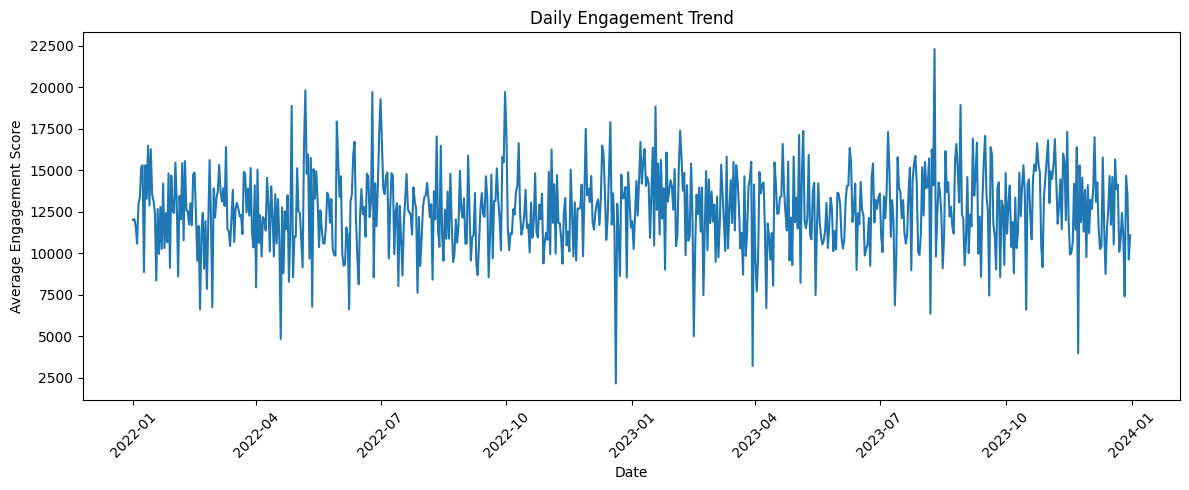

In [83]:
print('Line Plot')
# Convert posted_at into datetime format
df['posted_at'] = pd.to_datetime(df['posted_at'], errors='coerce')

# Create engagement score if not already created
df['engagement_score'] = (
    df['likes'] + df['comments'] + df['shares']
)

# Group engagement by date
daily_engagement = df.groupby(
    df['posted_at'].dt.date
)['engagement_score'].mean()

# Create line plot
plt.figure(figsize=(12, 5))

plt.plot(
    daily_engagement.index,
    daily_engagement.values
)

plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Average Engagement Score')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Bar Chart


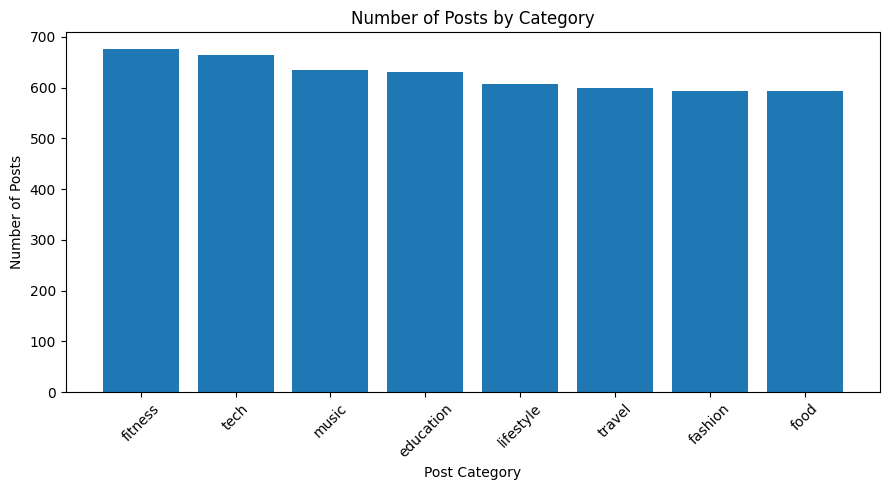

In [84]:
print('Bar Chart')
category_count = df['post_category'].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(category_count.index, category_count.values)

plt.title('Number of Posts by Category')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Pie Chart


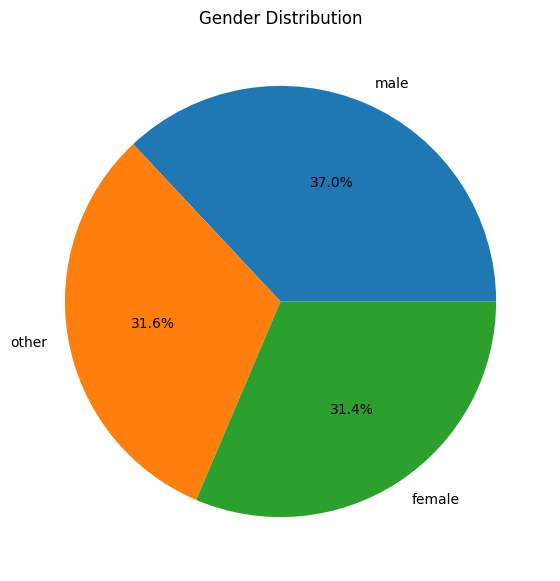

In [85]:
print('Pie Chart')
gender_count = df['gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_count.values,
    labels=gender_count.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')
plt.show()


Histogram


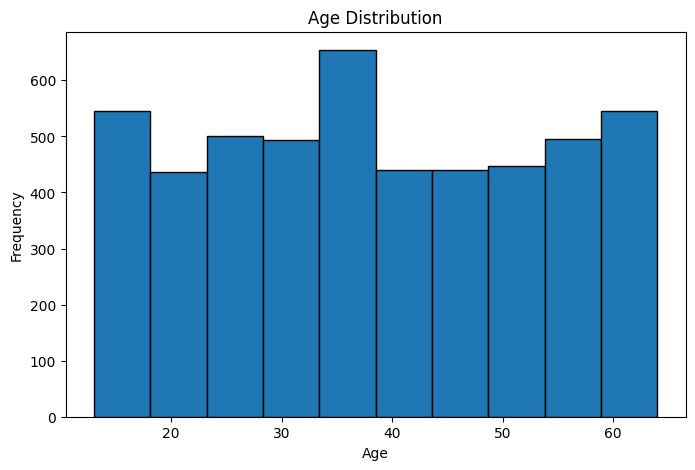

In [86]:
print("Histogram")
plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=10, edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()


Box plot


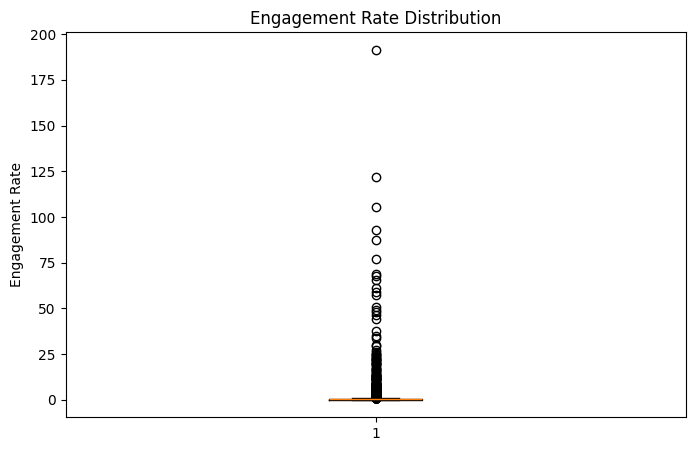

In [87]:
print("Box plot")
plt.figure(figsize=(8, 5))

plt.boxplot(df['engagement_rate'].dropna())

plt.title('Engagement Rate Distribution')
plt.ylabel('Engagement Rate')

plt.show()


Count plot


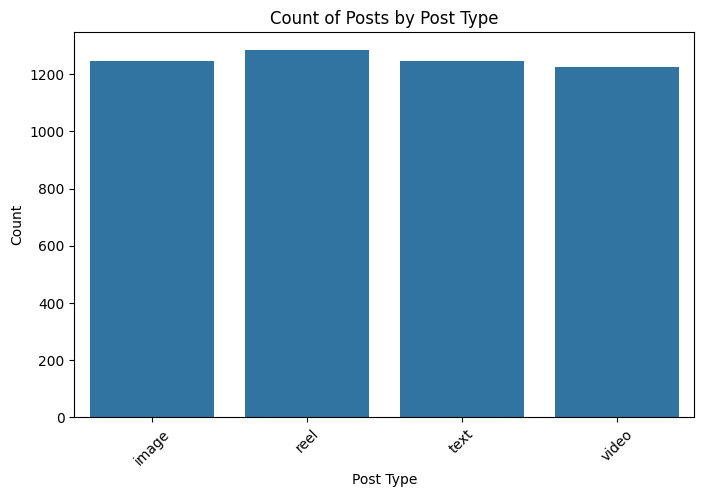

In [88]:
print("Count plot")
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='post_type')

plt.title('Count of Posts by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Count')

plt.xticks(rotation=45)
plt.show()


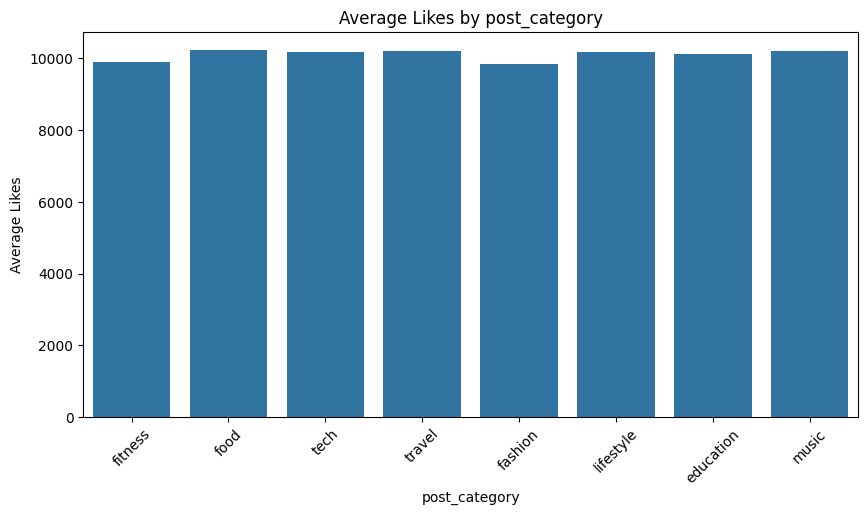

In [93]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.title('Average Likes by post_category')
plt.xlabel('category_count')
plt.ylabel('Average Likes')

plt.xticks(rotation=45)
plt.show()


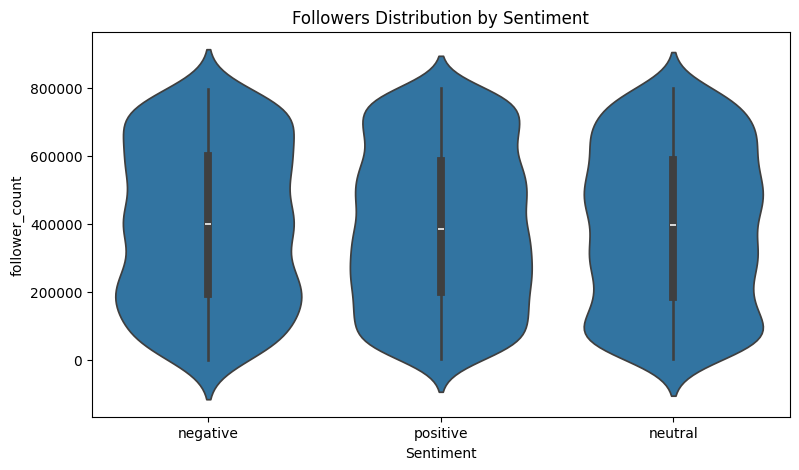

In [96]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.title('Followers Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('follower_count')

plt.show()

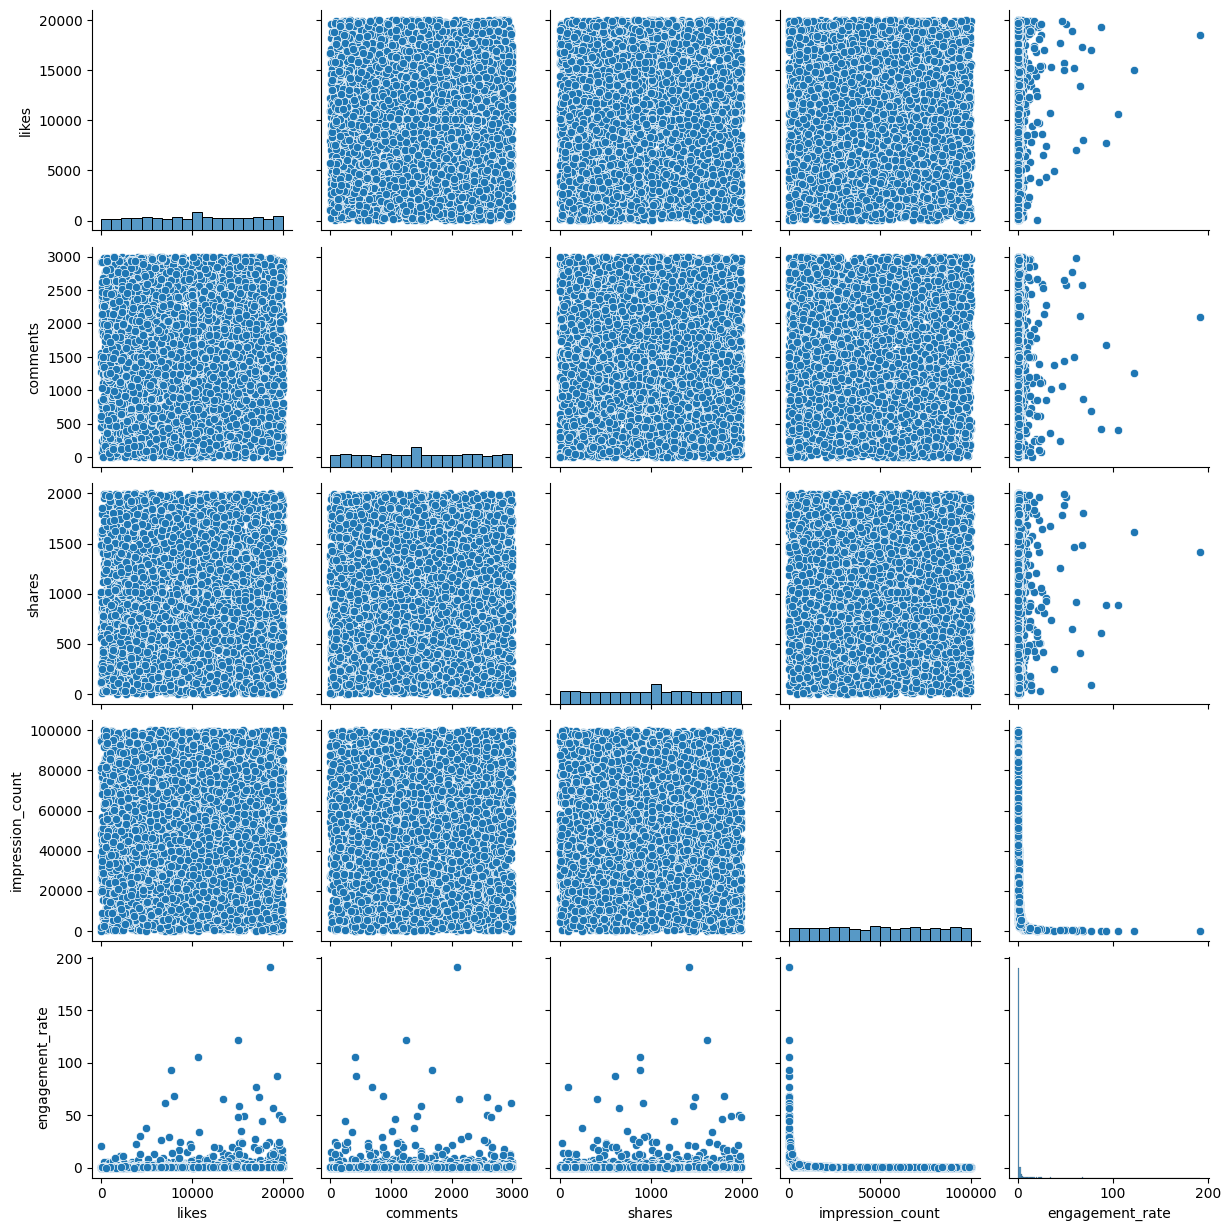

In [98]:

selected_columns = [
    'likes',
    'comments',
    'shares',
    'impression_count',
    'engagement_rate'
]

sns.pairplot(df[selected_columns].dropna())

plt.show()


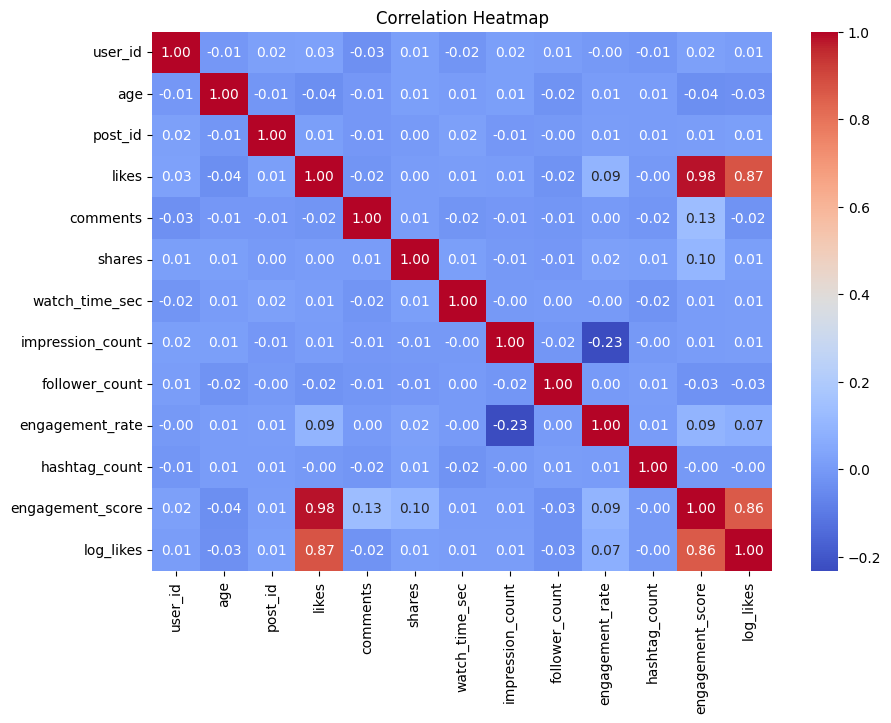

In [99]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()



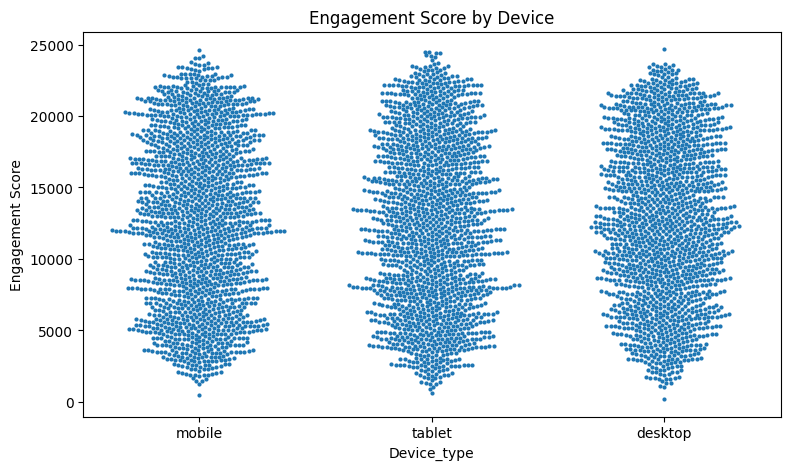

In [101]:

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=df,
    x='device_type',
    y='engagement_score',
    size=3
)

plt.title('Engagement Score by Device')
plt.xlabel('Device_type')
plt.ylabel('Engagement Score')

plt.show()


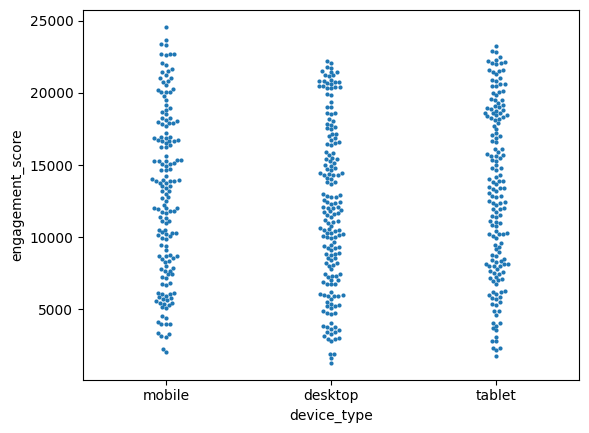

In [102]:
sample_df = df.sample(min(500, len(df)), random_state=42)

sns.swarmplot(
    data=sample_df,
    x='device_type',
    y='engagement_score',
    size=3
)

plt.show()

In [104]:

daily_df = (
    df.groupby('posted_at', as_index=False)['engagement_score']
    .mean()
)

fig = px.line(
    daily_df,
    x='posted_at',
    y='engagement_score',
    title='Interactive Daily Engagement Trend'
)

fig.show()


In [106]:

category_df = (
    df.groupby('post_category', as_index=False)['likes']
    .mean()
)

fig = px.bar(
    category_df,
    x='post_category',
    y='likes',
    title='Average Likes by Category'
)

fig.show()


In [107]:

fig = px.scatter(
    df,
    x='likes',
    y='comments',
    size='shares',
    color='post_type',
    hover_data=['country'],
    title='Social Media Engagement Bubble Chart'
)

fig.show()


In [108]:
post_performance = df.groupby('post_type')[
    'engagement_rate'
].mean().sort_values(ascending=False)

print(post_performance)

print("Best post type:", post_performance.idxmax())


post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64
Best post type: video


In [111]:
category_performance = df.groupby('post_category')[
    'engagement_rate'
].mean().sort_values(ascending=False)

print(category_performance)

print("Best category:", category_performance.idxmax())


post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64
Best category: food


In [112]:

country_performance = df.groupby('country')[
    'engagement_rate'
].mean().sort_values(ascending=False)

print(country_performance.head(10))


country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


In [113]:
country_performance = df.groupby('country')[
    'engagement_rate'
].mean().sort_values(ascending=False)

print(country_performance.head(10))


country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


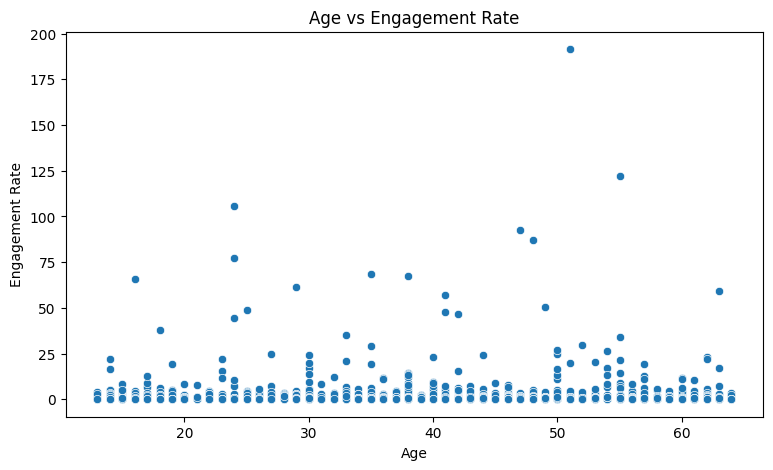

                      age  engagement_rate
age              1.000000         0.008039
engagement_rate  0.008039         1.000000


In [114]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='age',
    y='engagement_rate'
)

plt.title('Age vs Engagement Rate')
plt.xlabel('Age')
plt.ylabel('Engagement Rate')

plt.show()

print(df[['age', 'engagement_rate']].corr())

In [118]:
verified_performance = df.groupby('is_verified')[
    'engagement_rate'
].mean()

print(verified_performance)

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


In [124]:

df['hour'] = df['posted_at'].dt.hour

hourly_impressions = df.groupby('hour')[
    'impression_count'
].mean().sort_values(ascending=False)

print(hourly_impressions)

print("Best hour:", hourly_impressions.idxmax())


hour
0    0.0
Name: impression_count, dtype: float64
Best hour: 0


In [127]:

device_performance = df.groupby('device_type')[
    'watch_time_sec'
].mean().sort_values(ascending=False)

print(device_performance)

print("Best device:", device_performance.idxmax())


device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64
Best device: mobile


In [128]:

sentiment_performance = df.groupby('sentiment')[
    'engagement_rate'
].mean().sort_values(ascending=False)

print(sentiment_performance)

print("Best sentiment:", sentiment_performance.idxmax())


sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64
Best sentiment: negative


In [129]:

negative_neutral = df[
    df['sentiment'].isin(['negative', 'neutral'])
]

sentiment_analysis = negative_neutral.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

print(sentiment_analysis)


                  likes     comments       shares  engagement_rate
sentiment                                                         
negative   10208.096875  1516.094792  1007.307292         1.038486
neutral     9923.194499  1528.404060   996.565160         0.991170
